In [3]:
# %load_ext autoreload
%reload_ext autoreload
%autoreload 2

In [4]:
#!/usr/bin/env python3

import gtsam
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
%matplotlib widget
import numpy as np
np.set_printoptions(linewidth=np.inf, suppress=True)
import copy
import time
from pathlib import Path
import open3d as o3d
from scipy.spatial import KDTree

# Local imports
import common.FGVizHelpers as fgtools
from multiSession.SessionManager import SessionManager
from multiSession.SessionUpdater import SessionUpdater

from sparcification.NFR import GraphSparsification



Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


## Load and plot original graph

495


Text(0.5, 1.0, 'Aligned Via GPS Only')

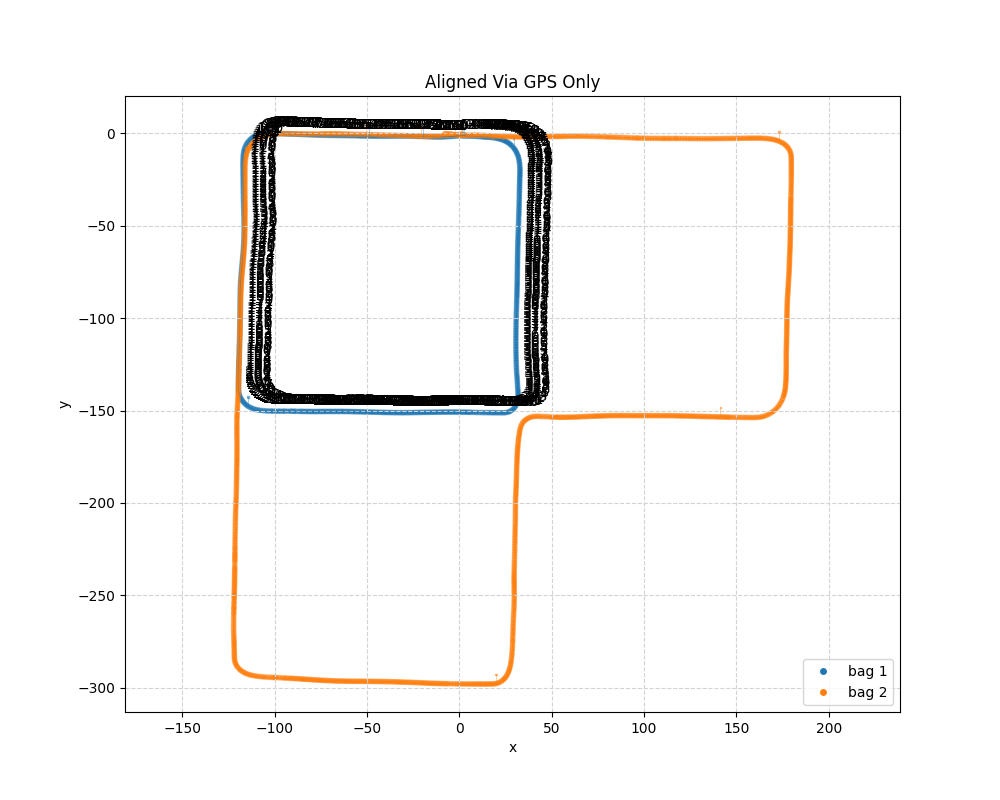

In [5]:
# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------
directory1 = Path("../../results/urban/around_block_initial/")
directory2 = Path("../../results/urban/around_block_short_reconnect/")
directory3 = Path("../../results/urban/quick_map_disconnect/")
fileName = "fullSavedGraph.g2o"

session1 = SessionManager(directory1 / fileName)
session2 = SessionManager(directory2 / fileName)
# session3 = SessionManager(directory3 / fileName)

session1.UpdateISAM2()
session2.UpdateISAM2()
# session3.UpdateISAM2()

session1.LoadScans(directory1 / "Scans")
session2.LoadScans(directory2 / "Scans")
# session3.LoadScans(directory3 / "Scans")

bag_colors = ['tab:blue', 'tab:orange', 'tab:green']

print(session1.graph.size())

ax = fgtools.plot_graph(session1.graph, session1.values, color_override=bag_colors[0], alpha=0.5, addKeyLabels=True)
# fgtools.plot_graph_covariances(session1.values.keys(), session1.graph, session1.values, ax=ax)

fgtools.plot_graph(session2.graph, session2.orig_values_, ax=ax, color_override=bag_colors[1], alpha=0.5)
# fgtools.plot_graph_covariances(session2.values.keys(), session2.graph, session2.values, ax=ax)

# fgtools.plot_graph(session3.graph, session3.values, ax=ax, color_override=bag_colors[2], alpha=0.5)
# fgtools.plot_graph_covariances(session3.values.keys(), session3.graph, session3.values, ax=ax)

legendElements = [
                    Line2D([0],[0], marker='o', color='w', label="bag 1", markerfacecolor=bag_colors[0]),
                    Line2D([0],[0], marker='o', color='w', label="bag 2", markerfacecolor=bag_colors[1]),
                    # Line2D([0],[0], marker='o', color='w', label="bag 3", markerfacecolor=bag_colors[2]),
                ]
ax.legend(handles=legendElements, loc='lower right')
ax.set_title("Aligned Via GPS Only")

# globalMap1 = session1.CreateGlobalPCD((1, 0, 0))
# globalMap2 = session2.CreateGlobalPCD((0, 1, 0))
# globalMap3 = session3.CreateGlobalPCD((0, 0, 1))

# o3d.visualization.draw_geometries([globalMap1, globalMap2, globalMap3])


In [6]:
session1.graph.size()

495

In [7]:
from common.weighted_pose_graph_class import WeightedPoseGraph

wpg = WeightedPoseGraph(session1.graph, session1.values)

In [15]:
wpg.compute_L()

<Compressed Sparse Row sparse array of dtype 'float64'
	with 1462 stored elements and shape (486, 486)>

Plotting graph


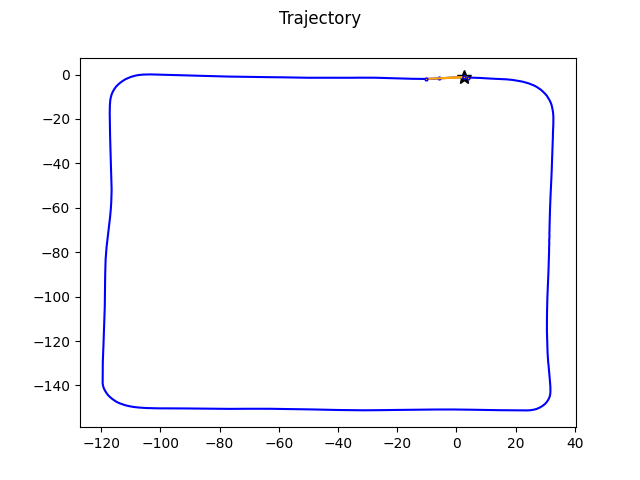

In [25]:
plt.close("all")
wpg.plot_graph()

In [26]:
wpg.compute_max_eig()

np.float64(185661.61602215652)

In [30]:
wpg.compute_algcon()

2.0032619428658496

## Test for Python Binding

In [8]:
import numpy as np
import gtsam
from gtsam import (
    NonlinearFactorGraph,
    Values,
    PriorFactorDouble,
    BetweenFactorDouble,
    noiseModel,
    FixedLagSmoother
)
from gtsam import IncrementalFixedLagSmoother
from gtsam.symbol_shorthand import X



# ---------------------------------------------------------
# Fixed lag size (seconds)
# Variables older than current_time - lag are marginalized
# ---------------------------------------------------------
lag = 5.0

smoother = IncrementalFixedLagSmoother(lag)

# Noise models
prior_noise = noiseModel.Isotropic.Sigma(1, 0.1)
odom_noise = noiseModel.Isotropic.Sigma(1, 0.2)
meas_noise = noiseModel.Isotropic.Sigma(1, 0.5)

dt = 1.0
velocity = 1.0

current_time = 0.0

for k in range(15):

    graph = NonlinearFactorGraph()
    values = Values()
    timestamps = {}

    key = X(k)

    # -----------------------------------------------------
    # Simulated ground truth
    # x_k = v * t
    # -----------------------------------------------------
    true_position = velocity * current_time

    # noisy measurement
    measured_position = (
        true_position + np.random.randn() * 0.5
    )

    # -----------------------------------------------------
    # Initialize estimate
    # -----------------------------------------------------
    initial_guess = measured_position
    values.insert(key, initial_guess)

    timestamps[key] = current_time

    # -----------------------------------------------------
    # Prior on first state
    # -----------------------------------------------------
    if k == 0:

        graph.add(
            PriorFactorDouble(
                key,
                0.0,
                prior_noise,
            )
        )

    else:

        prev_key = X(k - 1)

        # Constant velocity model:
        # x_k - x_{k-1} = v * dt
        graph.add(
            BetweenFactorDouble(
                prev_key,
                key,
                velocity * dt,
                odom_noise,
            )
        )

    # -----------------------------------------------------
    # Add measurement factor
    # This acts like a GPS measurement
    # -----------------------------------------------------
    graph.add(
        PriorFactorDouble(
            key,
            measured_position,
            meas_noise,
        )
    )

    # -----------------------------------------------------
    # Update smoother
    # -----------------------------------------------------
    smoother.update(
        graph,
        values,
        timestamps,
    )

    # -----------------------------------------------------
    # Get current estimate
    # -----------------------------------------------------
    result = smoother.calculateEstimate()

    print(f"\nTime step {k}")

    for j in range(max(0, k - 6), k + 1):

        test_key = X(j)

        if result.exists(test_key):

            estimate = result.atDouble(test_key)

            print(
                f"  x[{j}] = {estimate:.3f}"
            )

    current_time += dt





Time step 0
  x[0] = 0.008

Time step 1
  x[0] = 0.023
  x[1] = 1.086

Time step 2
  x[0] = 0.013
  x[1] = 1.030
  x[2] = 1.976

Time step 3
  x[0] = 0.003
  x[1] = 0.982
  x[2] = 1.882
  x[3] = 2.820

Time step 4
  x[0] = 0.006
  x[1] = 0.998
  x[2] = 1.912
  x[3] = 2.870
  x[4] = 3.898

Time step 5
  x[0] = 0.008
  x[1] = 1.005
  x[2] = 1.927
  x[3] = 2.896
  x[4] = 3.937
  x[5] = 4.958

Time step 6
  x[1] = 1.019
  x[2] = 1.955
  x[3] = 2.941
  x[4] = 4.008
  x[5] = 5.066
  x[6] = 6.120

Time step 7
  x[2] = 1.945
  x[3] = 2.925
  x[4] = 3.983
  x[5] = 5.027
  x[6] = 6.062
  x[7] = 7.033

Time step 8
  x[3] = 2.914
  x[4] = 3.965
  x[5] = 5.000
  x[6] = 6.021
  x[7] = 6.973
  x[8] = 7.943

Time step 9
  x[4] = 3.964
  x[5] = 4.998
  x[6] = 6.018
  x[7] = 6.968
  x[8] = 7.936
  x[9] = 8.932

Time step 10
  x[5] = 4.996
  x[6] = 6.015
  x[7] = 6.963
  x[8] = 7.928
  x[9] = 8.921
  x[10] = 9.915

Time step 11
  x[6] = 6.054
  x[7] = 7.022
  x[8] = 8.017
  x[9] = 9.053
  x[10] = 10.111

In [21]:

keysToCheck = session1.values.keys()[-2:]
isam = session1.isam_
start = time.time()
m1 = isam.jointMarginalCovariance(keysToCheck).fullMatrix()
print(f"Total time isam: {time.time() - start}")

Total time isam: 0.0002608299255371094


In [22]:
marg = gtsam.Marginals(session1.graph, session1.values)
start = time.time()
m2 = marg.jointMarginalCovariance(keysToCheck).fullMatrix()
print(f"Total time marg: {time.time() - start}")

Total time marg: 0.008079767227172852


In [19]:
np.allclose(m1, m2)

True

In [20]:
np.isclose(m1, m2)

array([[ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,

In [1]:
# Kiss ICP
import numpy as np
import gtsam

a = np.load("../results/latest/Scans_poses.npy")

In [2]:
values = gtsam.Values()
for i, b in enumerate(a):
    pose = gtsam.Pose3(b)
    values.insert(i, pose)

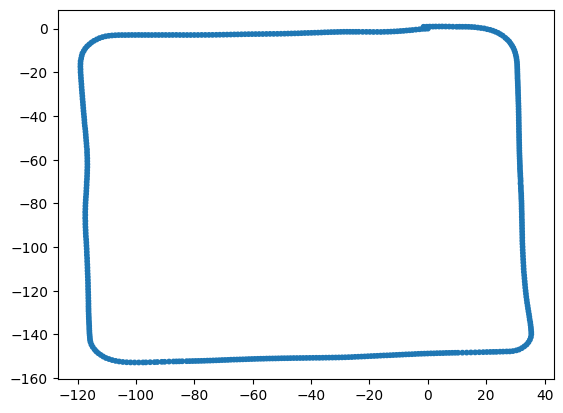

In [3]:
from common.FGVizHelpers import plot_points

plot_points(values.keys(), values)

In [ ]:
import kiss_icp.

In [5]:
dir(kiss_icp)

['__builtins__',
 '__cached__',
 '__doc__',
 '__file__',
 '__loader__',
 '__name__',
 '__package__',
 '__path__',
 '__spec__',
 '__version__']

In [7]:
from pathlib import Path

filePath = Path("./results/urban")
path2 = Path(filePath)
print(path2)

results/urban
